
# Laboratório 09 — Preparação de Imagens para IA

## Objetivo
Preparar imagens para utilização em modelos
de inteligência artificial e aprendizado de máquina.

## Conteúdos
- Padronização de dimensões
- Conversão de imagens em matrizes NumPy
- Normalização de pixels
- Organização dos dados para modelos de IA

## Ferramentas
- Python
- Pillow
- NumPy
- Matplotlib


Dimensões originais: (1021, 1600)
Dimensões padronizadas: (224, 224)
Formato da matriz: (224, 224, 3)


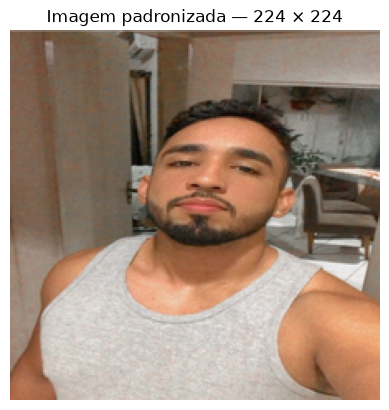

In [1]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Carregando a fotografia original
foto = Image.open("../imagens/PAULO.jpeg").convert("RGB")

# Padronizando as dimensões para 224 × 224 pixels
foto_padronizada = foto.resize(
    (224, 224),
    resample=Image.Resampling.LANCZOS
)

# Convertendo para matriz NumPy
matriz = np.array(foto_padronizada)

# Consultando as dimensões
print("Dimensões originais:", foto.size)
print("Dimensões padronizadas:", foto_padronizada.size)
print("Formato da matriz:", matriz.shape)

# Visualizando a imagem padronizada
plt.imshow(foto_padronizada)
plt.title("Imagem padronizada — 224 × 224")
plt.axis("off")
plt.show()


In [2]:

matriz_normalizada = matriz.astype("float32") / 255.0

print("Tipo original:", matriz.dtype)
print("Tipo normalizado:", matriz_normalizada.dtype)

print("Menor valor normalizado:", matriz_normalizada.min())
print("Maior valor normalizado:", matriz_normalizada.max())

print("Pixel original:", matriz[0, 0])
print("Pixel normalizado:", matriz_normalizada[0, 0])


Tipo original: uint8
Tipo normalizado: float32
Menor valor normalizado: 0.0
Maior valor normalizado: 0.9843137
Pixel original: [138 115 102]
Pixel normalizado: [0.5411765 0.4509804 0.4      ]


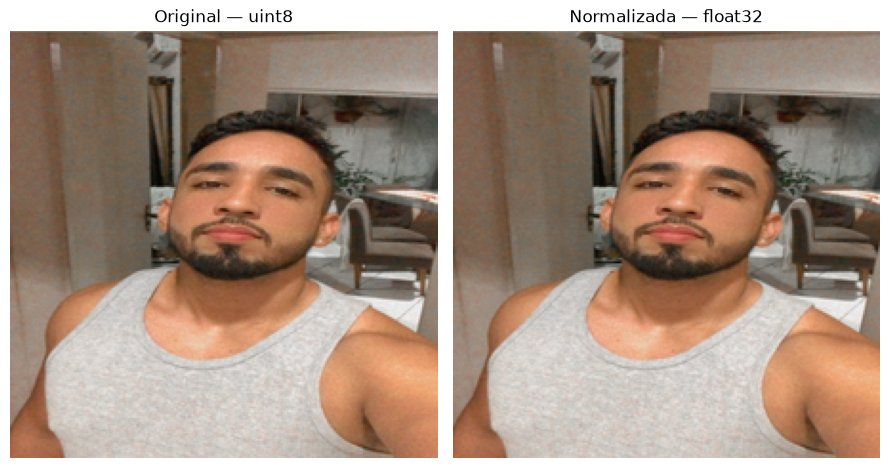

In [3]:

fig, eixos = plt.subplots(1, 2, figsize=(9, 5))

# Imagem original: valores de 0 a 255
eixos[0].imshow(matriz)
eixos[0].set_title("Original — uint8")
eixos[0].axis("off")

# Imagem normalizada: valores de 0 a 1
eixos[1].imshow(matriz_normalizada)
eixos[1].set_title("Normalizada — float32")
eixos[1].axis("off")

plt.tight_layout()
plt.show()


In [4]:

# Reconstruindo a escala original
matriz_recuperada = matriz_normalizada * 255.0

# Calculando a maior diferença entre os pixels
diferenca = np.abs(
    matriz.astype("float32") - matriz_recuperada
)

print("Maior diferença:", diferenca.max())
print("Diferença média:", diferenca.mean())

# Comparando o primeiro pixel
print("Original:", matriz[0, 0])
print("Recuperado:", matriz_recuperada[0, 0])


Maior diferença: 0.0
Diferença média: 0.0
Original: [138 115 102]
Recuperado: [138. 115. 102.]


In [5]:

# Adicionando a dimensão de batch
lote_imagens = np.expand_dims(
    matriz_normalizada,
    axis=0
)

print("Formato original:", matriz_normalizada.shape)
print("Formato com batch:", lote_imagens.shape)
print("Quantidade de imagens:", lote_imagens.shape[0])


Formato original: (224, 224, 3)
Formato com batch: (1, 224, 224, 3)
Quantidade de imagens: 1
